100%|██████████| 3.76k/3.76k [00:00<00:00, 6.19MB/s]

Extracting files...
Files: ['/root/.cache/kagglehub/datasets/vijayaadithyanvg/car-price-predictionused-cars/versions/1/car data.csv']
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']
(301, 9)
Missing values:
 Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64
Target column: Selling_Price


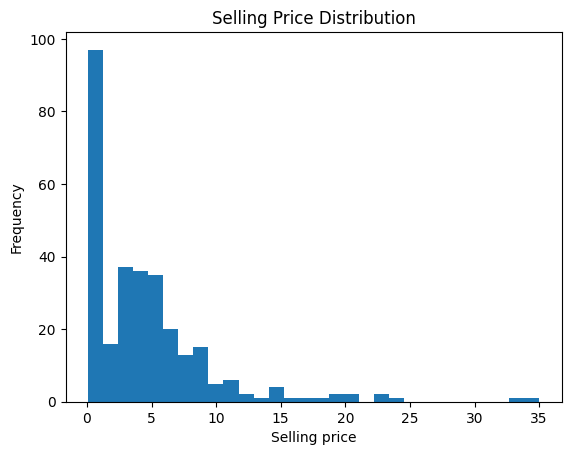

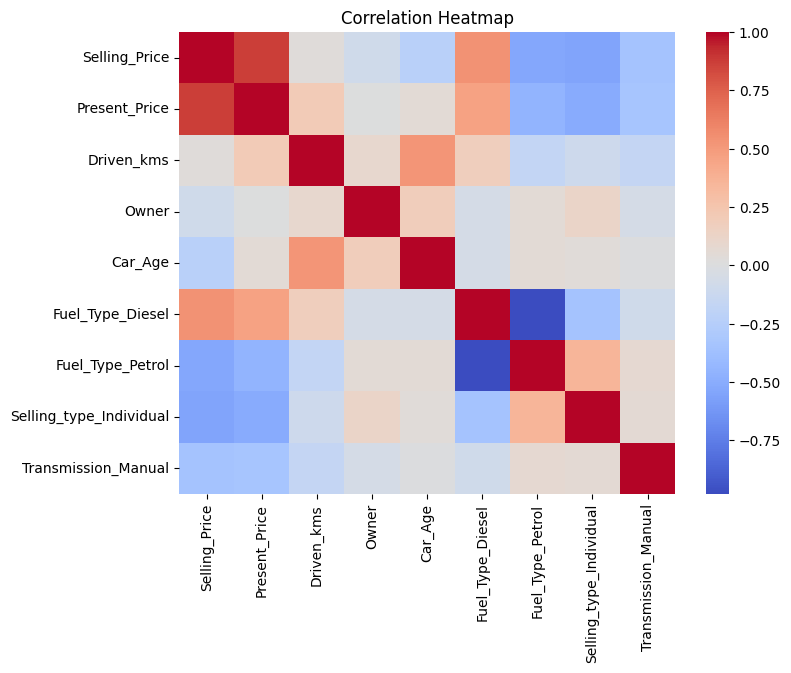

Linear Regression: R2 = 0.753, MAE = 1.47
Random Forest: R2 = 0.515, MAE = 1.48


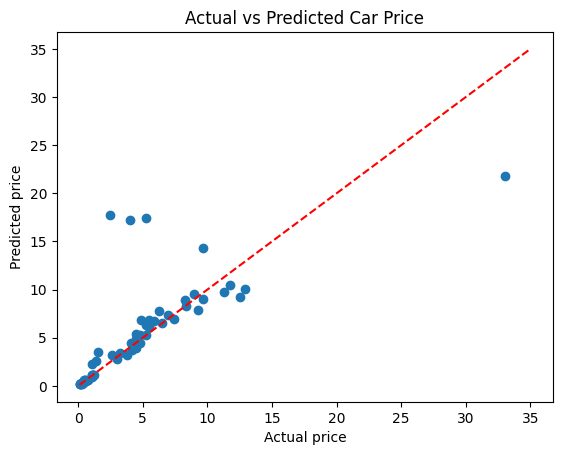

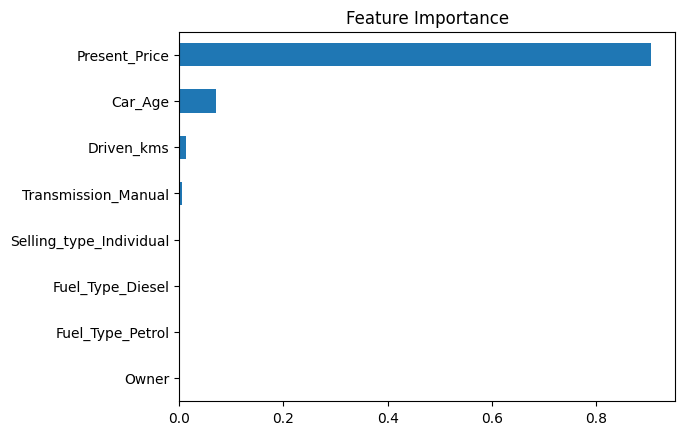

In [1]:
import kagglehub, os, glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

path = kagglehub.dataset_download("vijayaadithyanvg/car-price-predictionused-cars")
files = glob.glob(os.path.join(path, "*.csv"))
print("Files:", files)
df = pd.read_csv(files[0])
df.columns = df.columns.str.strip()
print(df.columns.tolist())
print(df.shape)
print("Missing values:\n", df.isnull().sum())

# Clean the data
df = df.dropna().drop_duplicates()

# Find the price column (target)
target = [c for c in df.columns if "selling" in c.lower() and "price" in c.lower()][0]
print("Target column:", target)

# Feature engineering: car age instead of year
if "Year" in df.columns:
    df["Car_Age"] = 2026 - df["Year"]
    df = df.drop(columns="Year")

# Car name has too many different values, so remove it
df = df.drop(columns=[c for c in df.columns if "name" in c.lower()], errors="ignore")

# Graph 1: price of cars
df[target].plot(kind="hist", bins=30, title="Selling Price Distribution")
plt.xlabel("Selling price")
plt.show()

# Turn text columns into numbers
df = pd.get_dummies(df, drop_first=True)

# Graph 2: correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Split the data
X = df.drop(columns=target)
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Train two models and compare them
models = {"Linear Regression": LinearRegression(),
          "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42)}
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    print(f"{name}: R2 = {r2_score(y_test, pred):.3f}, MAE = {mean_absolute_error(y_test, pred):.2f}")

# Graph 3: actual vs predicted (Random Forest)
best = models["Random Forest"]
pred = best.predict(X_test)
plt.scatter(y_test, pred)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs Predicted Car Price")
plt.show()

# Graph 4: which features matter most
pd.Series(best.feature_importances_, index=X.columns).sort_values().plot(
    kind="barh", title="Feature Importance")
plt.show()